## Decision Tree and Ensemble Learning Assignment

In [1]:
lazy import numpy as np
lazy import pandas as pd
lazy import matplotlib.pyplot as plt
lazy import seaborn as sns

lazy from sklearn.model_selection import train_test_split, GridSearchCV
lazy from sklearn.compose import ColumnTransformer
lazy from sklearn.pipeline import Pipeline
lazy from sklearn.preprocessing import OneHotEncoder
lazy from sklearn.impute import SimpleImputer
lazy from sklearn.tree import DecisionTreeRegressor
lazy from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
lazy from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 1. Load the housing dataset and inspect it

In [2]:
                                                       
df = pd.read_csv("Housing.csv")

print("Number of rows and columns:", df.shape)

Number of rows and columns: (21613, 21)


In [3]:
print("Data types of all attributes:")
display(df.dtypes.to_frame(name="Data Type"))

Data types of all attributes:


,Data Type
id,int64
date,str
price,float64
bedrooms,int64
bathrooms,float64
sqft_living,int64
sqft_lot,int64
floors,float64
waterfront,int64
view,int64


In [4]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

Missing values in each column:


,Missing Values
id,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0


In [5]:
display(df.head())

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7229300521,20141013T000000,231300.0,2,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


### 2. Select 800 random records and prepare the data

The target column is assumed to be `price`, as used in the common Housing.csv dataset. If your file uses a different target-column name, update `target_column` below.

In [6]:
target_column = "price"

if target_column not in df.columns:
    raise ValueError(
        f"Target column '{target_column}' was not found. "
        f"Available columns: {df.columns.tolist()}. "
        "Update target_column to the house-price column in your file."
    )

                                                                                  
df_sample = df.sample(n=min(800, len(df)), random_state=42).copy()

                                                
df_sample = df_sample.dropna(subset=[target_column])

print("Sampled dataset shape:", df_sample.shape)
display(df_sample.head())

Sampled dataset shape: (800, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
735,2591820310,20141006T000000,365000.0,4,2.25,2070,8893,2.0,0,0,...,8,2070,0,1986,0,98058,47.4388,-122.162,2390,7700
2830,7974200820,20140821T000000,865000.0,5,3.00,2900,6730,1.0,0,0,...,8,1830,1070,1977,0,98115,47.6784,-122.285,2370,6283
4106,7701450110,20140815T000000,1038000.0,4,2.50,3770,10893,2.0,0,2,...,11,3770,0,1997,0,98006,47.5646,-122.129,3710,9685
16218,9522300010,20150331T000000,1490000.0,3,3.50,4560,14608,2.0,0,2,...,12,4560,0,1990,0,98034,47.6995,-122.228,4050,14226
19964,9510861140,20140714T000000,711000.0,3,2.50,2550,5376,2.0,0,0,...,9,2550,0,2004,0,98052,47.6647,-122.083,2250,4050


In [7]:
                                     
X = df_sample.drop(columns=[target_column])
y = pd.to_numeric(df_sample[target_column], errors="coerce")

                                                           
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

                                             
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Records available for modelling:", len(X))

Numerical features: ['id', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
Categorical features: ['date']
Records available for modelling: 800


In [8]:
                                                                                                      
                                                                                         
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)
display(pd.DataFrame(
    X_train_processed[:5].toarray() if hasattr(X_train_processed, "toarray") else X_train_processed[:5],
    columns=feature_names
).head())

Training data after preprocessing: (640, 269)
Testing data after preprocessing: (160, 269)


d:\GitHub\CDAC\Machine Learning\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,num__id,num__bedrooms,num__bathrooms,num__sqft_living,num__sqft_lot,num__floors,num__waterfront,num__view,num__condition,num__grade,...,cat__date_20150429T000000,cat__date_20150430T000000,cat__date_20150502T000000,cat__date_20150504T000000,cat__date_20150505T000000,cat__date_20150506T000000,cat__date_20150507T000000,cat__date_20150508T000000,cat__date_20150511T000000,cat__date_20150512T000000
0,7.526800e+09,4.0,2.25,2500.0,10062.0,1.0,0.0,0.0,3.0,8.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,4.365700e+09,2.0,1.75,930.0,7080.0,1.0,0.0,0.0,3.0,6.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.446401e+09,2.0,1.00,930.0,6600.0,1.0,0.0,0.0,3.0,6.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.472700e+09,3.0,1.75,1710.0,8767.0,1.0,0.0,0.0,4.0,8.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,9.512200e+09,5.0,3.75,3090.0,4943.0,2.0,0.0,0.0,3.0,10.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 3. Define evaluation metrics

MAE measures average absolute prediction error. RMSE penalizes larger errors more strongly. R² measures how much target variation is explained by the model; higher R² is generally better, while lower MAE and RMSE are better.

In [9]:
def evaluate_model(name, model, X_train_data, X_test_data, y_train_data, y_test_data):
    model.fit(X_train_data, y_train_data)
    train_score = model.score(X_train_data, y_train_data)
    test_score = model.score(X_test_data, y_test_data)
    predictions = model.predict(X_test_data)

    return {
        "Model": name,
        "Training Score": train_score,
        "Testing Score": test_score,
        "MAE": mean_absolute_error(y_test_data, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_data, predictions)),
        "R2 Score": r2_score(y_test_data, predictions)
    }

### 4. Build and tune a Decision Tree Regressor

In [10]:
dt_model = DecisionTreeRegressor(random_state=42)

dt_results = evaluate_model(
    "Decision Tree", dt_model,
    X_train_processed, X_test_processed, y_train, y_test
)

print(dt_results)

{'Model': 'Decision Tree', 'Training Score': 1.0, 'Testing Score': 0.7365433800142542, 'MAE': 150225.65, 'RMSE': np.float64(228332.33267947403), 'R2 Score': 0.7365433800142542}


In [11]:
                                                        
dt_param_grid = {
    "max_depth": [None, 3, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

dt_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid=dt_param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)
dt_search.fit(X_train_processed, y_train)

tuned_dt_model = dt_search.best_estimator_
tuned_dt_results = evaluate_model(
    "Tuned Decision Tree", tuned_dt_model,
    X_train_processed, X_test_processed, y_train, y_test
)

print("Best Decision Tree parameters:", dt_search.best_params_)
print(tuned_dt_results)

Best Decision Tree parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}
{'Model': 'Tuned Decision Tree', 'Training Score': 0.8574626913123352, 'Testing Score': 0.6811996382855743, 'MAE': 142283.44751984128, 'RMSE': np.float64(251172.59837100748), 'R2 Score': 0.6811996382855743}


A decision tree can overfit when it grows too deep. Limiting `max_depth` and increasing `min_samples_leaf` can improve generalization. Compare the tuned model's test MAE, RMSE, and R² with the untuned model.

### 5. Build and tune a Random Forest Regressor

In [12]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_results = evaluate_model(
    "Random Forest", rf_model,
    X_train_processed, X_test_processed, y_train, y_test
)

print(rf_results)

{'Model': 'Random Forest', 'Training Score': 0.9573618390375633, 'Testing Score': 0.7811770708134357, 'MAE': 116387.91412499998, 'RMSE': np.float64(208093.86149096093), 'R2 Score': 0.7811770708134357}


In [13]:
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4]
}

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    scoring="neg_mean_squared_error",
    cv=5,
    n_jobs=-1
)
rf_search.fit(X_train_processed, y_train)

tuned_rf_model = rf_search.best_estimator_
tuned_rf_results = evaluate_model(
    "Tuned Random Forest", tuned_rf_model,
    X_train_processed, X_test_processed, y_train, y_test
)

print("Best Random Forest parameters:", rf_search.best_params_)
print(tuned_rf_results)

Best Random Forest parameters: {'max_depth': 20, 'min_samples_leaf': 2, 'n_estimators': 200}
{'Model': 'Tuned Random Forest', 'Training Score': 0.9392368435950544, 'Testing Score': 0.7967257235352619, 'MAE': 117395.71698319694, 'RMSE': np.float64(200564.5011103487), 'R2 Score': 0.7967257235352619}


Random Forest averages predictions from many decision trees, usually reducing the variance of a single tree. Use the held-out test metrics—not training score alone—to judge whether tuning helped.

### 6. Visualize the top 5 Random Forest feature importances

In [14]:
importances = tuned_rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

top5_features = importance_df.head(5)
display(top5_features)

,Feature,Importance
3,num__sqft_living,0.285576
9,num__grade,0.188390
15,num__lat,0.118512
7,num__view,0.090560
17,num__sqft_living15,0.077776


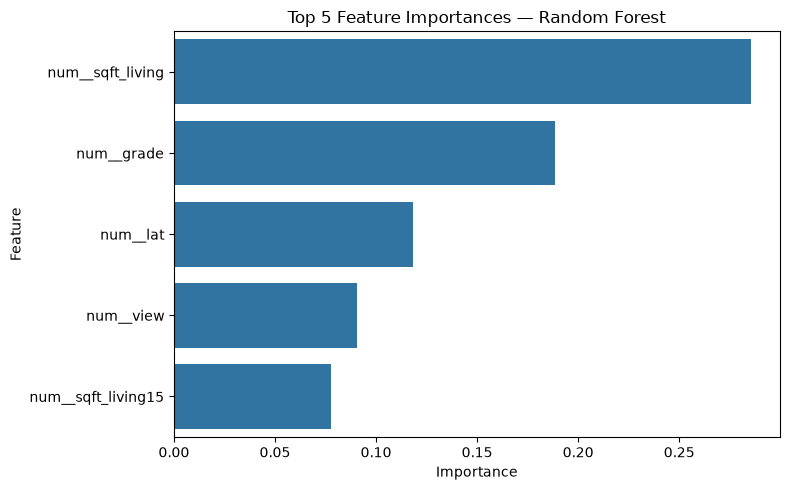

In [15]:
plt.figure(figsize=(8, 5))
sns.barplot(data=top5_features, x="Importance", y="Feature")
plt.title("Top 5 Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Feature importance indicates how much a feature contributes to the fitted forest's split-based reductions in impurity. It describes the model, not causation; correlated features can share or distort importance.

### 7. Implement an AdaBoost Regressor

In [16]:
                                                  
ada_model = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3, random_state=42),
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

ada_results = evaluate_model(
    "AdaBoost", ada_model,
    X_train_processed, X_test_processed, y_train, y_test
)

print(ada_results)

{'Model': 'AdaBoost', 'Training Score': 0.7925272248859685, 'Testing Score': 0.6936325605675473, 'MAE': 164071.13732507857, 'RMSE': np.float64(246226.14123848273), 'R2 Score': 0.6936325605675473}


AdaBoost combines sequential weak learners, giving more attention to observations that previous learners predicted poorly. Evaluate it using test MAE, RMSE, and R²; its performance depends on the dataset and can be affected by outliers.

### 8. Build a Gradient Boosting Regressor

In [17]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_results = evaluate_model(
    "Gradient Boosting", gb_model,
    X_train_processed, X_test_processed, y_train, y_test
)

print("Training Score:", gb_results["Training Score"])
print("Testing Score:", gb_results["Testing Score"])
print("MAE:", gb_results["MAE"])
print("RMSE:", gb_results["RMSE"])
print("R2 Score:", gb_results["R2 Score"])

Training Score: 0.9576480996241254
Testing Score: 0.8522368708417611
MAE: 111416.18224375954
RMSE: 170999.915345487
R2 Score: 0.8522368708417611


Gradient Boosting adds trees sequentially, with each new tree attempting to correct errors made by the current ensemble. A much higher training score than testing score can indicate overfitting.

### 9. Compare all regression models

In [18]:
comparison_rows = [
    dt_results,
    tuned_dt_results,
    {
        **evaluate_model(
            "Bagging",
            BaggingRegressor(
                estimator=DecisionTreeRegressor(random_state=42),
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            ),
            X_train_processed, X_test_processed, y_train, y_test
        )
    },
    rf_results,
    tuned_rf_results,
    ada_results,
    gb_results
]

comparison_df = pd.DataFrame(comparison_rows)
comparison_df = comparison_df.sort_values("RMSE", ascending=True).reset_index(drop=True)
display(comparison_df.round(4))

,Model,Training Score,Testing Score,MAE,RMSE,R2 Score
0,Gradient Boosting,0.9576,0.8522,111416.1822,170999.9153,0.8522
1,Tuned Random Forest,0.9392,0.7967,117395.7170,200564.5011,0.7967
2,Bagging,0.9571,0.7858,116179.5470,205897.8649,0.7858
3,Random Forest,0.9574,0.7812,116387.9141,208093.8615,0.7812
4,Decision Tree,1.0000,0.7365,150225.6500,228332.3327,0.7365
5,AdaBoost,0.7925,0.6936,164071.1373,246226.1412,0.6936
6,Tuned Decision Tree,0.8575,0.6812,142283.4475,251172.5984,0.6812


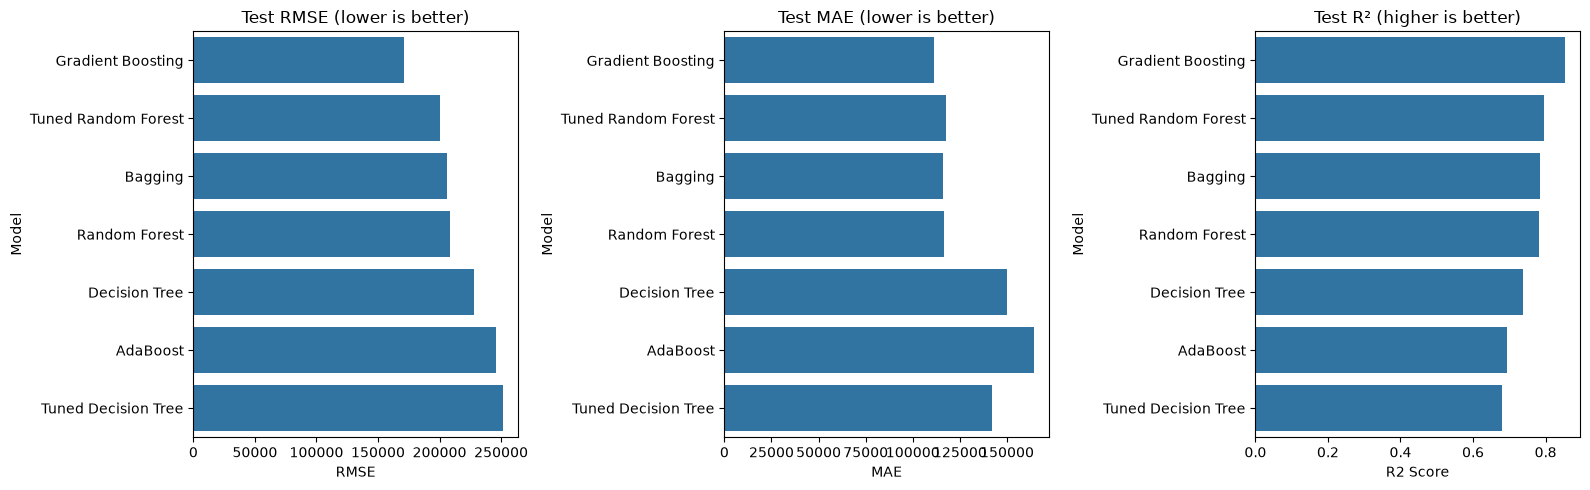

In [19]:
                                                    
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(data=comparison_df, x="RMSE", y="Model", ax=axes[0])
axes[0].set_title("Test RMSE (lower is better)")

sns.barplot(data=comparison_df, x="MAE", y="Model", ax=axes[1])
axes[1].set_title("Test MAE (lower is better)")

sns.barplot(data=comparison_df, x="R2 Score", y="Model", ax=axes[2])
axes[2].set_title("Test R² (higher is better)")

plt.tight_layout()
plt.show()

### Conclusion

Compare the models using the same train/test split. Prefer a model with lower test MAE and RMSE and higher test R², while also checking the gap between training and testing scores for overfitting. The best model cannot be known in advance; it depends on the actual Housing.csv data and the resulting metrics.